<a href="https://colab.research.google.com/github/juvowen/AlgoTrading/blob/main/LeafResearch_PhysicsPrediction.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**Can Physcis Help us predict how volital an asset is?**
  - Modeling Price Movement Through Heat Diffusion and Liquidity Fields

Price movement is influenced by the distribution of liquidity, trading activity, and volatility. By representing these variables as a dynamic heat field, we may identify price regions that attract or resist future price movement.

Concentration: Where is the majority of trading activity occurring?



Pressure: Where is there an imbalance between buyers and sellers?



Diffusion: How does trading activity spread or change across price levels over time?

**GOAL:**

When will volatility rise? Detect warning signs that the market is approaching a high volatility period.



How long will it last? Estimate how many days volatility may remain elevated.



When will it cool? Estimate when volatility is likely to return to its normal range.

**HYPOTHESIS:**

Financial markets have volatility patterns that can be studied like heat transfer: volatility builds, spreads across time, persists, and eventually dissipates.

In [ ]:
import yfinance as yf
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [ ]:
# Step 1 : Pick stock to trade & clean data
spx = yf.download("^SPX",period="5y", interval="1d",auto_adjust=True,
    progress=False)
spx

Price,Close,High,Low,Open,Volume
Ticker,^SPX,^SPX,^SPX,^SPX,^SPX
Date,,,,,
2021-11-02,4630.649902,4635.149902,4613.339844,4613.339844,3975250000
2021-11-03,4660.569824,4663.459961,4621.189941,4630.649902,4319660000
2021-11-04,4680.060059,4683.000000,4662.589844,4662.930176,4462300000
2021-11-05,4697.529785,4718.500000,4681.319824,4699.259766,4467180000
2021-11-08,4701.700195,4714.919922,4694.390137,4701.479980,4269710000
...,...,...,...,...,...
2026-10-27,7722.600098,7736.240234,7677.160156,7699.470215,5160120000
2026-10-28,7743.979980,7758.430176,7718.370117,7735.560059,5466960000


S&P 500 THERMAL STATUS
----------------------------------------
HOT threshold: 19.85%
COLD threshold: 10.20%
Current volatility: 11.73%
Current state: NORMAL

COLD EPISODE STATISTICS
----------------------------------------
Completed cold episodes: 27
Average cold duration: 9.15 days
Median cold duration: 5.00 days
Longest cold duration: 36 days


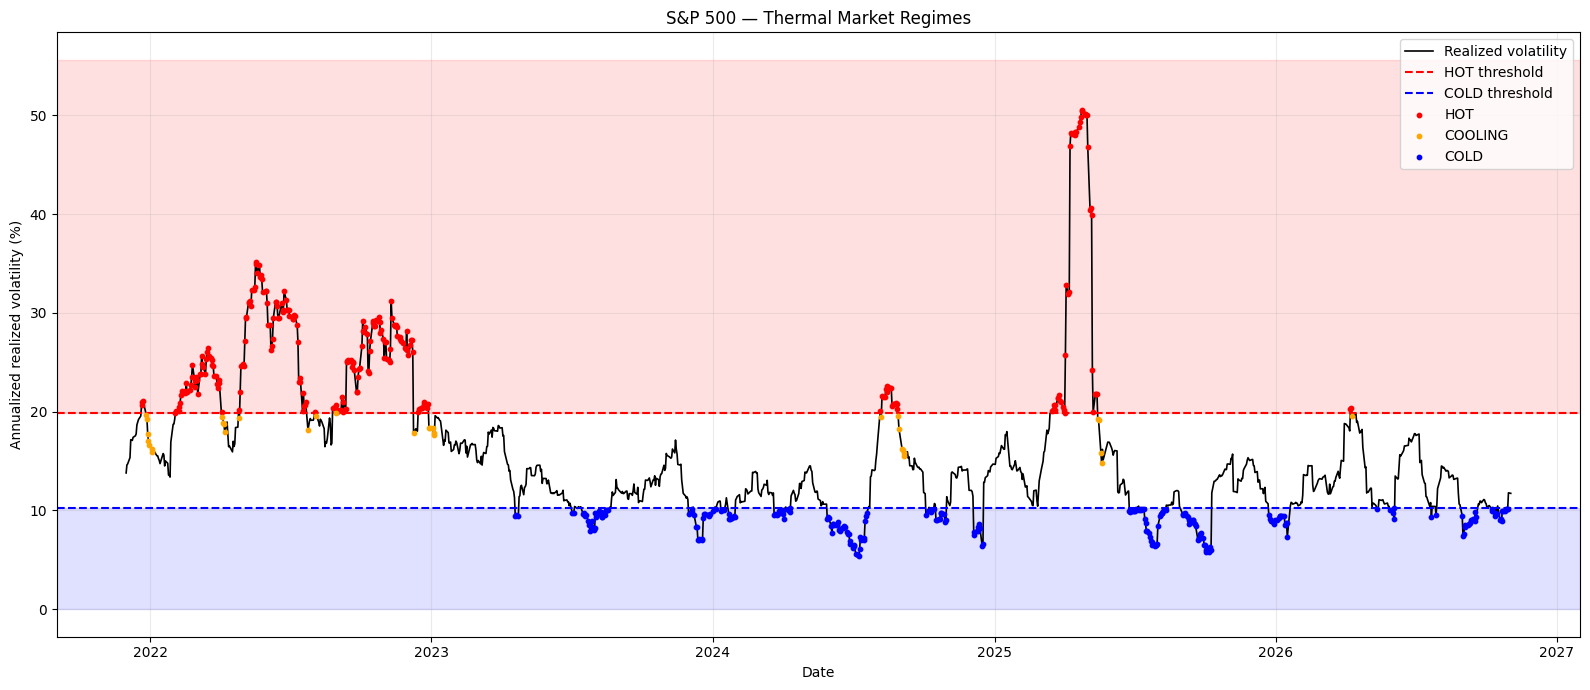

In [ ]:
#Step 2: this stock is very liquid , this stock is illiquid

# ==========================================
# 1. CALCULATE REALIZED VOLATILITY
# ==========================================

close = spx["Close"].squeeze().dropna()

returns = np.log(close / close.shift(1))

vol = returns.rolling(20).std() * np.sqrt(252) * 100
vol = vol.dropna()

# ==========================================
# 2. DEFINE HOT AND COLD THRESHOLDS
# ==========================================

HOT_PERCENTILE = 0.80
COLD_PERCENTILE = 0.20

hot_threshold = vol.quantile(HOT_PERCENTILE)
cold_threshold = vol.quantile(COLD_PERCENTILE)

# ==========================================
# 3. CLASSIFY MARKET REGIMES
# ==========================================

data = pd.DataFrame({"Vol": vol})

data["State"] = "NORMAL"

data.loc[data["Vol"] >= hot_threshold, "State"] = "HOT"

data.loc[data["Vol"] <= cold_threshold, "State"] = "COLD"

# Cooling = volatility declining after a HOT episode,
# until it reaches the COLD threshold or starts rising again.
cooling = False
states = []

for i in range(len(data)):

    current_vol = data["Vol"].iloc[i]
    previous_vol = data["Vol"].iloc[i-1] if i > 0 else np.nan

    if current_vol >= hot_threshold:
        cooling = False
        state = "HOT"

    elif current_vol <= cold_threshold:
        cooling = False
        state = "COLD"

    elif (
        i > 0
        and current_vol < previous_vol
        and (
            cooling
            or (i > 0 and data["State"].iloc[i-1] == "HOT")
        )
    ):
        cooling = True
        state = "COOLING"

    elif cooling and current_vol < previous_vol:
        state = "COOLING"

    else:
        cooling = False
        state = "NORMAL"

    states.append(state)

data["State"] = states

# ==========================================
# 4. PRINT CURRENT MARKET CONDITION
# ==========================================

print("S&P 500 THERMAL STATUS")
print("-" * 40)

print(f"HOT threshold: {hot_threshold:.2f}%")
print(f"COLD threshold: {cold_threshold:.2f}%")
print(f"Current volatility: {data['Vol'].iloc[-1]:.2f}%")

print(f"Current state: {data['State'].iloc[-1]}")

# ==========================================
# 5. IDENTIFY COLD EPISODES
# ==========================================

cold = data["State"] == "COLD"

episode_id = cold.ne(cold.shift()).cumsum()

cold_episodes = (
    data[cold]
    .groupby(episode_id[cold])
    .agg(
        Start=("Vol", lambda x: x.index[0]),
        End=("Vol", lambda x: x.index[-1]),
        Duration=("Vol", "size")
    )
)

# Exclude the ongoing episode from completed duration statistics
if len(cold_episodes) > 0 and cold.iloc[-1]:
    completed_cold = cold_episodes.iloc[:-1]
else:
    completed_cold = cold_episodes

print("\nCOLD EPISODE STATISTICS")
print("-" * 40)

if len(completed_cold) > 0:
    durations = completed_cold["Duration"]

    print(f"Completed cold episodes: {len(durations)}")
    print(f"Average cold duration: {durations.mean():.2f} days")
    print(f"Median cold duration: {durations.median():.2f} days")
    print(f"Longest cold duration: {durations.max()} days")
else:
    print("Not enough completed cold episodes.")

# ==========================================
# 6. VISUALIZE THE THREE REGIMES
# ==========================================

fig, ax = plt.subplots(figsize=(16, 7))

ax.plot(
    data.index,
    data["Vol"],
    color="black",
    linewidth=1.2,
    label="Realized volatility"
)

ax.axhline(
    hot_threshold,
    color="red",
    linestyle="--",
    label="HOT threshold"
)

ax.axhline(
    cold_threshold,
    color="blue",
    linestyle="--",
    label="COLD threshold"
)

ax.axhspan(
    hot_threshold,
    data["Vol"].max() * 1.1,
    color="red",
    alpha=0.12
)

ax.axhspan(
    0,
    cold_threshold,
    color="blue",
    alpha=0.12
)

# Highlight individual states
for state, color in [
    ("HOT", "red"),
    ("COOLING", "orange"),
    ("COLD", "blue")
]:

    mask = data["State"] == state

    ax.scatter(
        data.index[mask],
        data.loc[mask, "Vol"],
        color=color,
        s=10,
        label=state,
        zorder=3
    )

ax.set_title("S&P 500 — Thermal Market Regimes")
ax.set_ylabel("Annualized realized volatility (%)")
ax.set_xlabel("Date")
ax.legend()
ax.grid(alpha=0.25)

plt.tight_layout()
plt.show()


In [ ]:


# ==========================================
# 1. CALCULATE REALIZED VOLATILITY
# ==========================================

close = spx["Close"].squeeze().dropna()

returns = np.log(close / close.shift(1))

vol = returns.rolling(20).std() * np.sqrt(252) * 100
vol = vol.dropna()

data = pd.DataFrame({"Vol": vol})

# ==========================================
# 2. DYNAMIC HOT / COLD THRESHOLDS
# ==========================================

LOOKBACK = 252
MIN_PERIODS = 126

HOT_PERCENTILE = 0.80
COLD_PERCENTILE = 0.20

# Shift(1) ensures today's thresholds use only prior data.
data["Hot_Threshold"] = (
    data["Vol"].shift(1)
    .rolling(LOOKBACK, min_periods=MIN_PERIODS)
    .quantile(HOT_PERCENTILE)
)

data["Cold_Threshold"] = (
    data["Vol"].shift(1)
    .rolling(LOOKBACK, min_periods=MIN_PERIODS)
    .quantile(COLD_PERCENTILE)
)

data = data.dropna().copy()

# ==========================================
# 3. CLASSIFY MARKET THERMAL STATES
# ==========================================

states = []
previous_state = "NORMAL"

for _, row in data.iterrows():

    current_vol = row["Vol"]
    hot_threshold = row["Hot_Threshold"]
    cold_threshold = row["Cold_Threshold"]

    if current_vol >= hot_threshold:
        current_state = "HOT"

    elif previous_state == "HOT":
        current_state = "COOLING"

    elif previous_state == "COOLING":

        if current_vol <= cold_threshold:
            current_state = "COLD"
        else:
            current_state = "COOLING"

    elif previous_state == "COLD":

        if current_vol > cold_threshold:
            current_state = "NORMAL"
        else:
            current_state = "COLD"

    elif current_vol <= cold_threshold:
        current_state = "COLD"

    else:
        current_state = "NORMAL"

    states.append(current_state)
    previous_state = current_state

data["State"] = states

# ==========================================
# 4. IDENTIFY CONSECUTIVE REGIME EPISODES
# ==========================================

data["Episode_ID"] = (
    data["State"].ne(data["State"].shift()).cumsum()
)

episodes = (
    data.groupby(["Episode_ID", "State"])
    .agg(
        Start=("Vol", lambda x: x.index[0]),
        End=("Vol", lambda x: x.index[-1]),
        Duration=("Vol", "size")
    )
    .reset_index()
)

# Exclude the currently active episode from completed samples.
current_state = data["State"].iloc[-1]
current_episode_id = data["Episode_ID"].iloc[-1]

completed_episodes = episodes[
    episodes["Episode_ID"] != current_episode_id
]

current_age = int(
    (data["Episode_ID"] == current_episode_id).sum()
)

# ==========================================
# 5. DURATION ANALYSIS
# ==========================================

def analyze_regime(regime):

    historical = completed_episodes[
        completed_episodes["State"] == regime
    ]["Duration"].to_numpy(dtype=int)

    current_duration = data[
        data["State"] == regime
    ]

    print(f"\n--- {regime} REGIME ---")

    if len(historical) == 0:
        print("Not enough completed historical episodes.")
        return

    print(f"Completed historical episodes: {len(historical)}")
    print(f"Average duration: {historical.mean():.2f} days")
    print(f"Median duration: {np.median(historical):.2f} days")
    print(f"Longest duration: {historical.max()} days")

    if current_state == regime:

        comparable = historical[historical >= current_age]

        print(f"\nCurrent episode age: {current_age} days")

        if len(comparable) > 0:

            remaining = comparable - current_age

            print(
                f"Expected additional duration: "
                f"{remaining.mean():.2f} days"
            )

            print(
                f"Median additional duration: "
                f"{np.median(remaining):.2f} days"
            )

            for days in [1, 3, 5, 10]:

                probability = np.mean(
                    comparable >= current_age + days
                )

                print(
                    f"Probability of remaining in {regime} "
                    f"for {days} more days: {probability:.1%}"
                )

        else:
            print("No historical episodes lasted this long.")

# ==========================================
# 6. CURRENT MARKET REPORT
# ==========================================

print("=" * 50)
print("       S&P 500 THERMAL MARKET MONITOR")
print("=" * 50)

print(f"\nCurrent volatility: {data['Vol'].iloc[-1]:.2f}%")
print(f"Current HOT threshold: {data['Hot_Threshold'].iloc[-1]:.2f}%")
print(f"Current COLD threshold: {data['Cold_Threshold'].iloc[-1]:.2f}%")

print(f"\nCURRENT STATE: {current_state}")
print(f"Current state duration: {current_age} trading days")

for regime in ["HOT", "COOLING", "COLD"]:
    analyze_regime(regime)

print("\n" + "=" * 50)

# ==========================================
# 7. VISUALIZE THERMAL REGIMES
# ==========================================

fig, ax = plt.subplots(figsize=(15, 7))

ax.plot(
    data.index,
    data["Vol"],
    linewidth=1.4,
    label="20-day Realized Volatility"
)

ax.plot(
    data.index,
    data["Hot_Threshold"],
    linestyle="--",
    linewidth=1.3,
    label="Dynamic HOT threshold"
)

ax.plot(
    data.index,
    data["Cold_Threshold"],
    linestyle="--",
    linewidth=1.3,
    label="Dynamic COLD threshold"
)

# Shade HOT and COLD regions.
ax.fill_between(
    data.index,
    data["Vol"],
    data["Hot_Threshold"],
    where=data["State"].eq("HOT"),
    alpha=0.30,
    label="HOT"
)

ax.fill_between(
    data.index,
    data["Vol"],
    data["Cold_Threshold"],
    where=data["State"].eq("COLD"),
    alpha=0.30,
    label="COLD"
)

# Mark COOLING observations.
cooling = data["State"] == "COOLING"

ax.scatter(
    data.index[cooling],
    data.loc[cooling, "Vol"],
    s=12,
    label="COOLING",
    zorder=3
)

ax.set_title("S&P 500 Thermal Market Regimes")
ax.set_xlabel("Date")
ax.set_ylabel("Annualized Realized Volatility (%)")

ax.legend()
ax.grid(alpha=0.25)

plt.tight_layout()
plt.show()

# ==========================================
# 8. EPISODE DURATION DISTRIBUTIONS
# ==========================================

fig, axes = plt.subplots(1, 3, figsize=(16, 4))

for ax, regime in zip(axes, ["HOT", "COOLING", "COLD"]):

    durations = completed_episodes[
        completed_episodes["State"] == regime
    ]["Duration"].to_numpy(dtype=int)

    if len(durations) > 0:

        ax.hist(
            durations,
            bins=min(15, max(3, len(durations))),
            edgecolor="black",
            alpha=0.75
        )

        ax.axvline(
            durations.mean(),
            linestyle="--",
            linewidth=2,
            label=f"Mean: {durations.mean():.1f} days"
        )

        ax.axvline(
            np.median(durations),
            linestyle=":",
            linewidth=2,
            label=f"Median: {np.median(durations):.1f} days"
        )

        ax.legend()

    else:
        ax.text(
            0.5, 0.5,
            "Insufficient episodes",
            ha="center",
            va="center",
            transform=ax.transAxes
        )

    ax.set_title(f"{regime} Episode Duration")
    ax.set_xlabel("Trading days")
    ax.set_ylabel("Number of episodes")
    ax.grid(alpha=0.25)

plt.tight_layout()
plt.show()



NameError: name 'spx' is not defined


========== BACKTEST RESULTS ==========



,Total Return,CAGR,Annual Volatility,Sharpe Ratio,Max Drawdown,Market Exposure
Buy & Hold,75.49%,13.63%,16.20%,0.87,-19.36%,100.00%
Sell at Cooling Entry,37.02%,7.42%,14.58%,0.56,-24.37%,82.87%
Sell after 2 Cooling Days,40.68%,8.06%,14.75%,0.60,-24.98%,84.49%



========== TRADE STATISTICS ==========

Sell at Cooling Entry
Position changes: 36
One-way trades: 36

Sell after 2 Cooling Days
Position changes: 32
One-way trades: 32



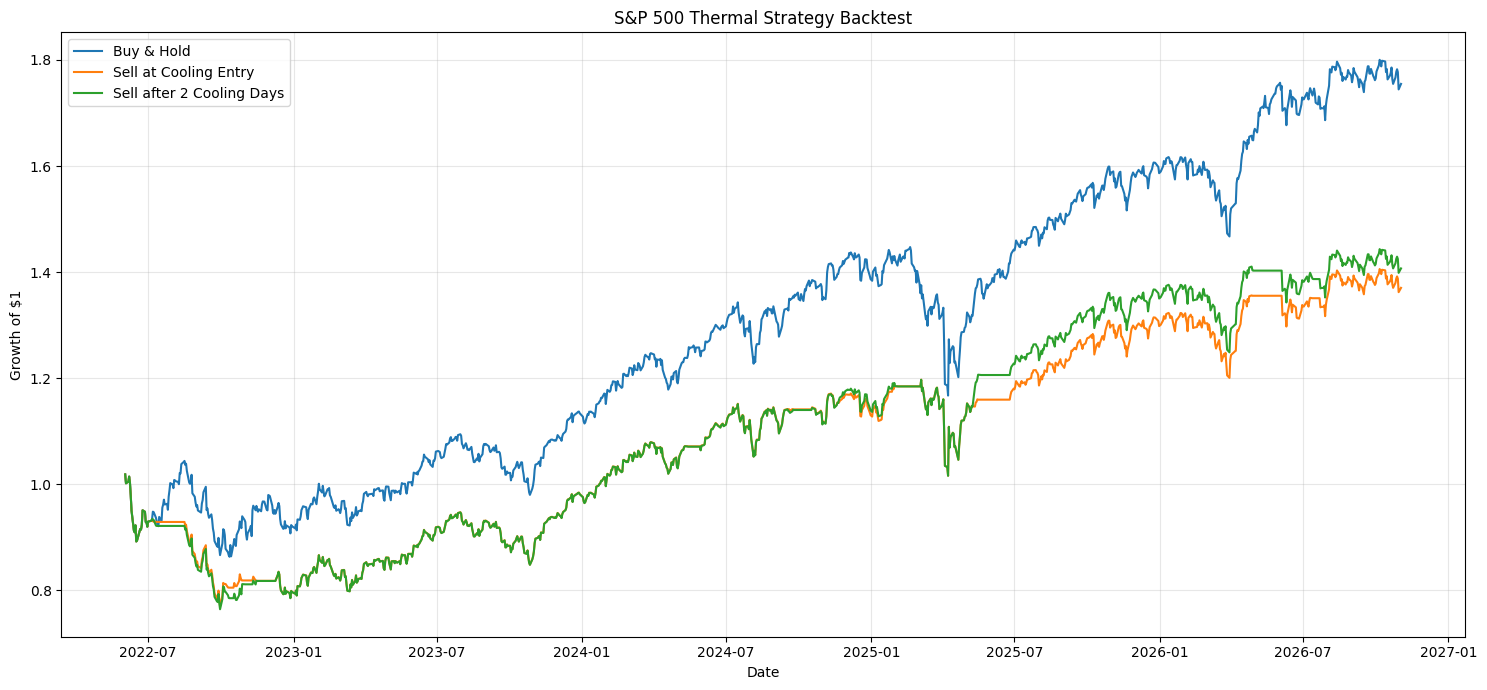

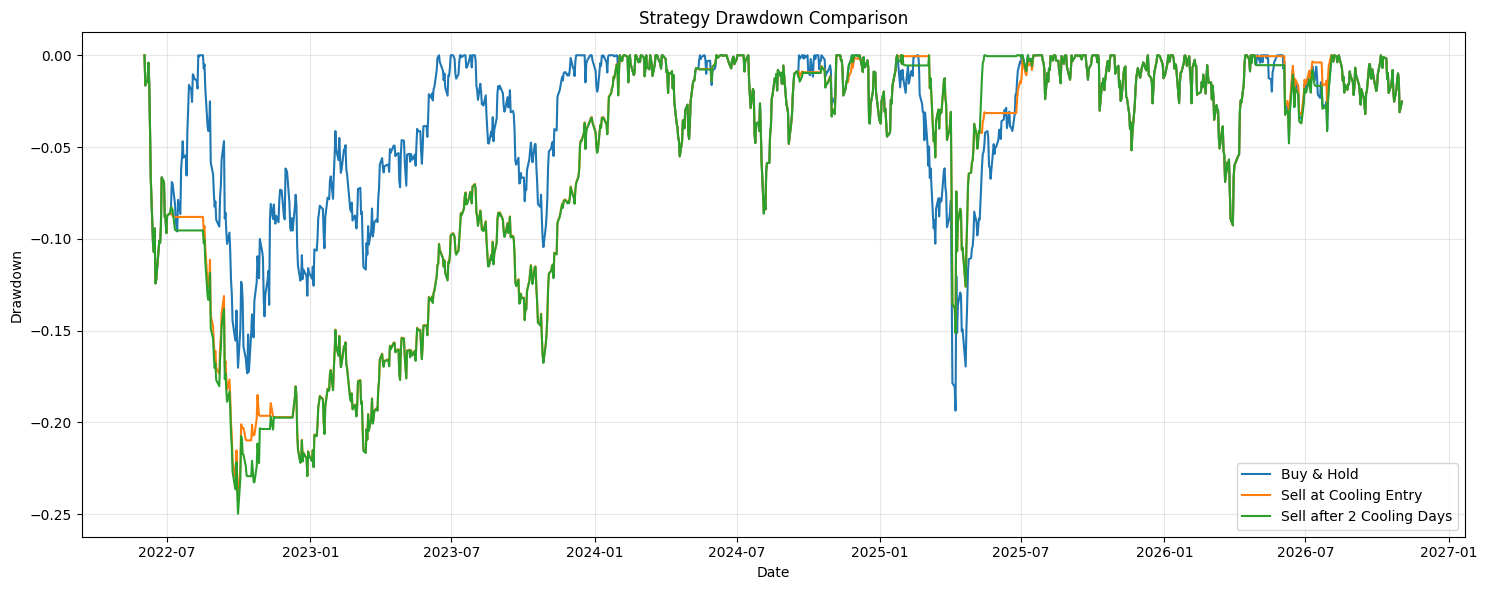

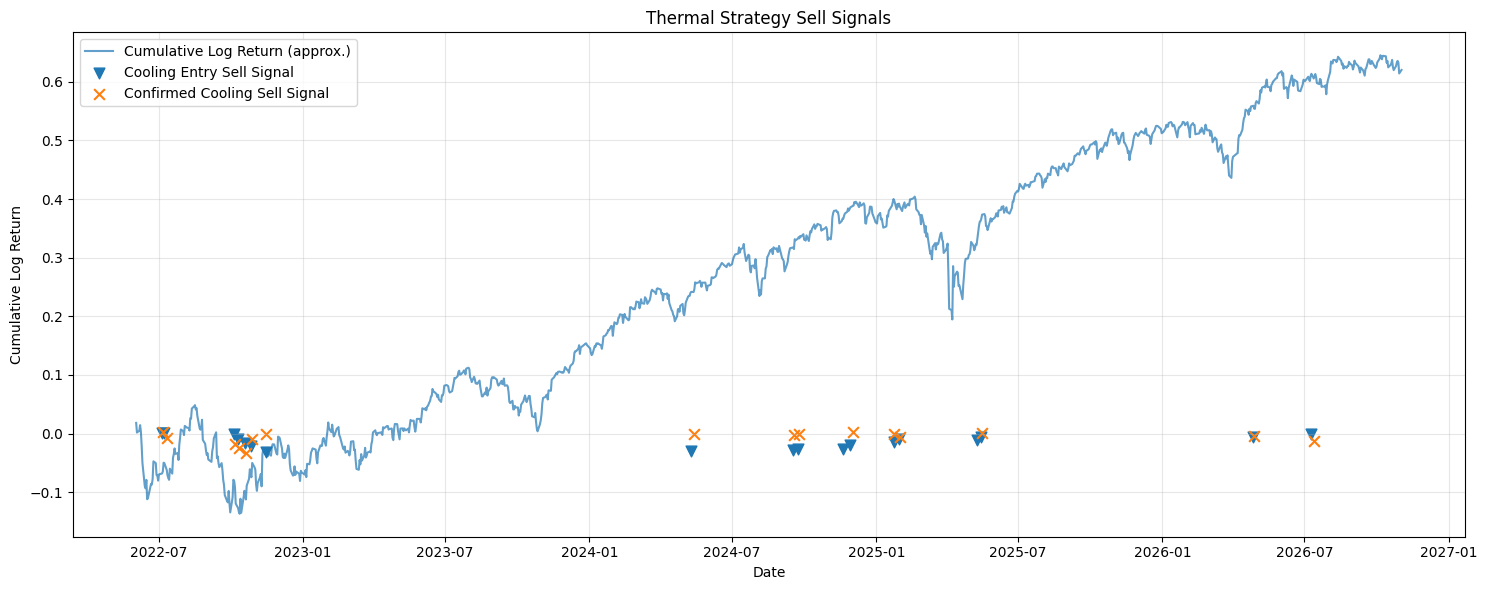

In [ ]:
#backtest - selling when stock cools down


import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ==========================================
# 1. PREPARE BACKTEST DATA
# ==========================================

bt = data[["State"]].join(
    returns.rename("Return"),
    how="inner"
).dropna()

# Strategy 1: Sell on the FIRST day of COOLING.
bt["Cooling_Entry"] = (
    bt["State"].eq("COOLING") &
    bt["State"].shift(1).ne("COOLING")
)

# Strategy 2: Sell after TWO consecutive COOLING days.
bt["Cooling_Confirmed"] = (
    bt["State"].eq("COOLING")
    .rolling(2)
    .sum()
    .eq(2)
)

# ==========================================
# 2. GENERATE POSITION SIGNALS
# ==========================================

# Position = 1: Invested in S&P 500
# Position = 0: Cash

# STRATEGY 1:
# Exit immediately when COOLING begins.
# Re-enter when COOLING ends.

bt["Position_Entry"] = np.where(
    bt["State"].eq("COOLING"),
    0,
    1
)

# STRATEGY 2:
# Wait for 2 consecutive COOLING days before exiting.
# Remain in cash until COOLING ends.

position = 1
positions = []

for _, row in bt.iterrows():

    if row["Cooling_Confirmed"]:
        position = 0

    elif row["State"] != "COOLING":
        position = 1

    positions.append(position)

bt["Position_Confirmed"] = positions

# ==========================================
# 3. EXECUTION TIMING
# ==========================================

# Signals generated at today's close.
# Position takes effect on the NEXT trading day.

bt["Held_Entry"] = bt["Position_Entry"].shift(1).fillna(1)
bt["Held_Confirmed"] = bt["Position_Confirmed"].shift(1).fillna(1)

# ==========================================
# 4. TRANSACTION COSTS
# ==========================================

# Assumed one-way transaction cost: 0.05%
# Change this to match your actual execution assumptions.

TRANSACTION_COST = 0.0005

bt["Turnover_Entry"] = (
    bt["Held_Entry"].diff().abs().fillna(0)
)

bt["Turnover_Confirmed"] = (
    bt["Held_Confirmed"].diff().abs().fillna(0)
)

# ==========================================
# 5. CALCULATE STRATEGY RETURNS
# ==========================================

bt["Buy_Hold"] = bt["Return"]

bt["Strategy_Entry"] = (
    bt["Held_Entry"] * bt["Return"]
    - bt["Turnover_Entry"] * TRANSACTION_COST
)

bt["Strategy_Confirmed"] = (
    bt["Held_Confirmed"] * bt["Return"]
    - bt["Turnover_Confirmed"] * TRANSACTION_COST
)

# ==========================================
# 6. EQUITY CURVES
# ==========================================

bt["Equity_Buy_Hold"] = (1 + bt["Buy_Hold"]).cumprod()

bt["Equity_Entry"] = (
    1 + bt["Strategy_Entry"]
).cumprod()

bt["Equity_Confirmed"] = (
    1 + bt["Strategy_Confirmed"]
).cumprod()

# ==========================================
# 7. PERFORMANCE METRICS
# ==========================================

def performance_metrics(returns_series, position):

    r = returns_series.dropna()

    equity = (1 + r).cumprod()

    total_return = equity.iloc[-1] - 1

    years = len(r) / 252

    cagr = (
        equity.iloc[-1] ** (1 / years) - 1
        if years > 0 else np.nan
    )

    annual_volatility = r.std() * np.sqrt(252)

    sharpe = (
        r.mean() / r.std() * np.sqrt(252)
        if r.std() > 0 else np.nan
    )

    drawdown = equity / equity.cummax() - 1

    max_drawdown = drawdown.min()

    return {
        "Total Return": total_return,
        "CAGR": cagr,
        "Annual Volatility": annual_volatility,
        "Sharpe Ratio": sharpe,
        "Max Drawdown": max_drawdown,
        "Market Exposure": position.mean()
    }


results = pd.DataFrame({
    "Buy & Hold": performance_metrics(
        bt["Buy_Hold"],
        pd.Series(1, index=bt.index)
    ),

    "Sell at Cooling Entry": performance_metrics(
        bt["Strategy_Entry"],
        bt["Held_Entry"]
    ),

    "Sell after 2 Cooling Days": performance_metrics(
        bt["Strategy_Confirmed"],
        bt["Held_Confirmed"]
    )
}).T

# Format as percentages where appropriate.
print("\n========== BACKTEST RESULTS ==========\n")

display(
    results.style.format({
        "Total Return": "{:.2%}",
        "CAGR": "{:.2%}",
        "Annual Volatility": "{:.2%}",
        "Sharpe Ratio": "{:.2f}",
        "Max Drawdown": "{:.2%}",
        "Market Exposure": "{:.2%}"
    })
)

# ==========================================
# 8. TRADE STATISTICS
# ==========================================

print("\n========== TRADE STATISTICS ==========\n")

for name, turnover in [
    ("Sell at Cooling Entry", bt["Turnover_Entry"]),
    ("Sell after 2 Cooling Days", bt["Turnover_Confirmed"])
]:

    exits = (turnover > 0).sum()
    total_trades = turnover.sum()

    print(name)
    print(f"Position changes: {exits}")
    print(f"One-way trades: {total_trades:.0f}")
    print()

# ==========================================
# 9. EQUITY CURVE COMPARISON
# ==========================================

plt.figure(figsize=(15, 7))

plt.plot(
    bt.index,
    bt["Equity_Buy_Hold"],
    label="Buy & Hold",
    linewidth=1.5
)

plt.plot(
    bt.index,
    bt["Equity_Entry"],
    label="Sell at Cooling Entry",
    linewidth=1.5
)

plt.plot(
    bt.index,
    bt["Equity_Confirmed"],
    label="Sell after 2 Cooling Days",
    linewidth=1.5
)

plt.title("S&P 500 Thermal Strategy Backtest")
plt.xlabel("Date")
plt.ylabel("Growth of $1")

plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# ==========================================
# 10. DRAWDOWN COMPARISON
# ==========================================

plt.figure(figsize=(15, 6))

for column, label in [
    ("Equity_Buy_Hold", "Buy & Hold"),
    ("Equity_Entry", "Sell at Cooling Entry"),
    ("Equity_Confirmed", "Sell after 2 Cooling Days")
]:

    equity = bt[column]
    drawdown = equity / equity.cummax() - 1

    plt.plot(
        drawdown.index,
        drawdown,
        label=label
    )

plt.title("Strategy Drawdown Comparison")
plt.xlabel("Date")
plt.ylabel("Drawdown")

plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# ==========================================
# 11. VISUALIZE SELL SIGNALS
# ==========================================

plt.figure(figsize=(15, 6))

plt.plot(
    bt.index,
    bt["Return"].cumsum(),
    label="Cumulative Log Return (approx.)",
    alpha=0.7
)

entry_signals = bt[bt["Cooling_Entry"]]
confirmed_signals = bt[
    bt["Cooling_Confirmed"] &
    bt["Cooling_Confirmed"].shift(1).ne(True)
]

plt.scatter(
    entry_signals.index,
    bt.loc[entry_signals.index, "Return"].cumsum(),
    marker="v",
    label="Cooling Entry Sell Signal",
    s=60
)

plt.scatter(
    confirmed_signals.index,
    bt.loc[confirmed_signals.index, "Return"].cumsum(),
    marker="x",
    label="Confirmed Cooling Sell Signal",
    s=60
)

plt.title("Thermal Strategy Sell Signals")
plt.xlabel("Date")
plt.ylabel("Cumulative Log Return")

plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


/tmp/ipykernel_603/2350400431.py:15: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  ~bt["Cold"].shift(1).fillna(False)


,Total Return,CAGR,Annual Volatility,Sharpe Ratio,Max Drawdown,Market Exposure
Buy & Hold,75.49%,13.63%,16.20%,0.87,-19.36%,100.00%
Sell at Cold Entry,69.18%,12.69%,14.45%,0.90,-19.36%,67.81%
Sell after 2 Cold Days,72.18%,13.14%,14.66%,0.92,-19.36%,70.60%


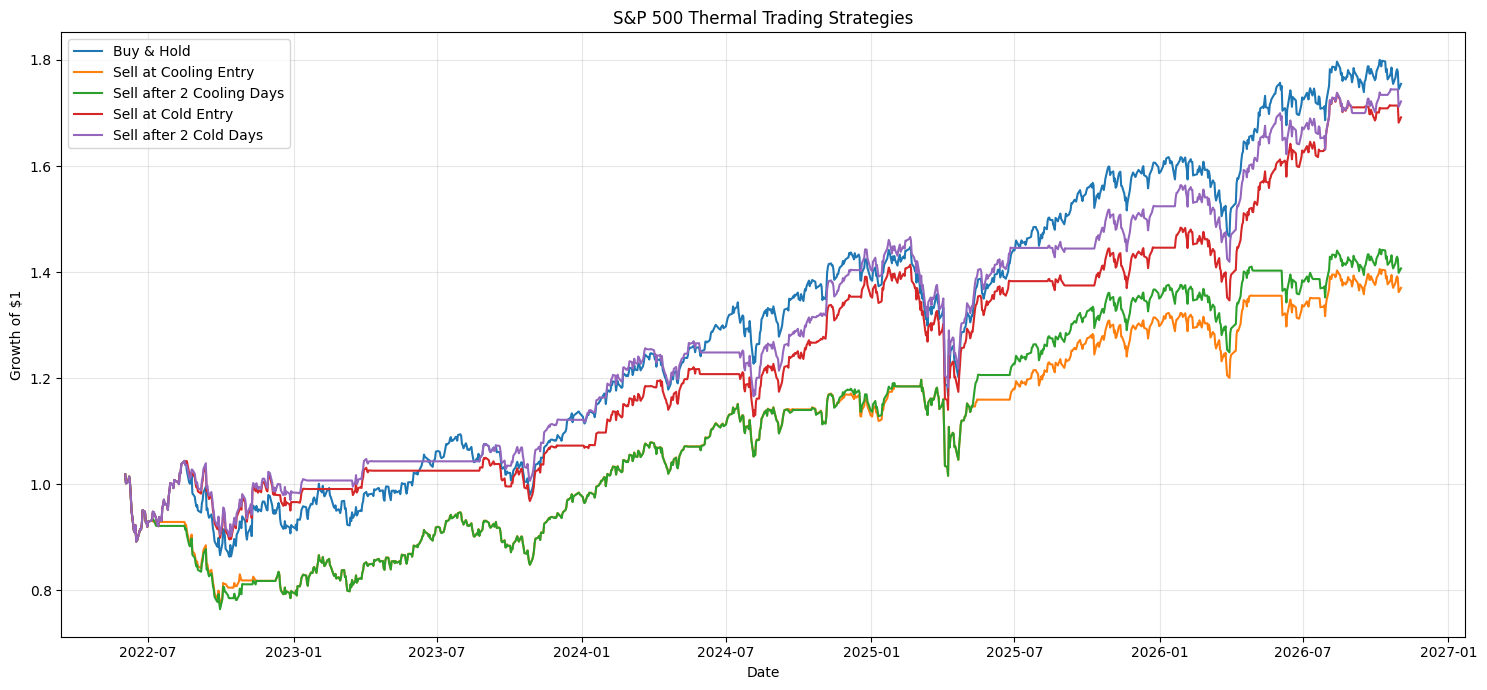

In [ ]:

# ==========================================
# 12. COLD THRESHOLD STRATEGIES
# ==========================================

# Identify when volatility is at or below the COLD threshold.
bt["Cold"] = (
    data.loc[bt.index, "Vol"]
    <= data.loc[bt.index, "Cold_Threshold"]
)

# STRATEGY 3: SELL IMMEDIATELY AT COLD ENTRY

bt["Cold_Entry"] = (
    bt["Cold"] &
    ~bt["Cold"].shift(1).fillna(False)
)

# Exit during every COLD day; re-enter when COLD ends.
bt["Position_Cold_Entry"] = (~bt["Cold"]).astype(int)


# STRATEGY 4: SELL AFTER 2 CONSECUTIVE COLD DAYS

bt["Cold_Confirmed"] = (
    bt["Cold"]
    .rolling(2)
    .sum()
    .eq(2)
)

# Stay invested until 2 consecutive COLD days occur.
# Stay in cash until the COLD regime ends.

position = 1
positions = []

for _, row in bt.iterrows():

    if row["Cold_Confirmed"]:
        position = 0

    elif not row["Cold"]:
        position = 1

    positions.append(position)

bt["Position_Cold_2D"] = positions


# ==========================================
# 13. EXECUTION TIMING
# ==========================================

# Signals at today's close, execution next trading day.

bt["Held_Cold_Entry"] = (
    bt["Position_Cold_Entry"].shift(1).fillna(1)
)

bt["Held_Cold_2D"] = (
    bt["Position_Cold_2D"].shift(1).fillna(1)
)


# ==========================================
# 14. CALCULATE RETURNS
# ==========================================

bt["Turnover_Cold_Entry"] = (
    bt["Held_Cold_Entry"].diff().abs().fillna(0)
)

bt["Turnover_Cold_2D"] = (
    bt["Held_Cold_2D"].diff().abs().fillna(0)
)

bt["Strategy_Cold_Entry"] = (
    bt["Held_Cold_Entry"] * bt["Return"]
    - bt["Turnover_Cold_Entry"] * TRANSACTION_COST
)

bt["Strategy_Cold_2D"] = (
    bt["Held_Cold_2D"] * bt["Return"]
    - bt["Turnover_Cold_2D"] * TRANSACTION_COST
)


# ==========================================
# 15. EQUITY CURVES
# ==========================================

bt["Equity_Cold_Entry"] = (
    1 + bt["Strategy_Cold_Entry"]
).cumprod()

bt["Equity_Cold_2D"] = (
    1 + bt["Strategy_Cold_2D"]
).cumprod()


# ==========================================
# 16. UPDATED PERFORMANCE COMPARISON
# ==========================================

results = pd.DataFrame({

    "Buy & Hold": performance_metrics(
        bt["Buy_Hold"],
        pd.Series(1, index=bt.index)
    ),

    "Sell at Cold Entry": performance_metrics(
        bt["Strategy_Cold_Entry"],
        bt["Held_Cold_Entry"]
    ),

    "Sell after 2 Cold Days": performance_metrics(
        bt["Strategy_Cold_2D"],
        bt["Held_Cold_2D"]
    )

}).T

display(
    results.style.format({
        "Total Return": "{:.2%}",
        "CAGR": "{:.2%}",
        "Annual Volatility": "{:.2%}",
        "Sharpe Ratio": "{:.2f}",
        "Max Drawdown": "{:.2%}",
        "Market Exposure": "{:.2%}"
    })
)


# ==========================================
# 17. EQUITY CURVE COMPARISON
# ==========================================

plt.figure(figsize=(15, 7))

for column, label in [
    ("Equity_Buy_Hold", "Buy & Hold"),
    ("Equity_Entry", "Sell at Cooling Entry"),
    ("Equity_Confirmed", "Sell after 2 Cooling Days"),
    ("Equity_Cold_Entry", "Sell at Cold Entry"),
    ("Equity_Cold_2D", "Sell after 2 Cold Days")
]:

    plt.plot(
        bt.index,
        bt[column],
        label=label,
        linewidth=1.5
    )

plt.title("S&P 500 Thermal Trading Strategies")
plt.xlabel("Date")
plt.ylabel("Growth of $1")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()



,Total Return,CAGR,Annual Volatility,Sharpe Ratio,Max Drawdown,Market Exposure
Buy & Hold,75.49%,13.63%,16.20%,0.87,-19.36%,100.00%
Buy at Cold Entry,-2.50%,-0.57%,7.34%,-0.04,-11.86%,32.19%
Buy after 2 Cold Days,-2.47%,-0.57%,6.93%,-0.05,-9.42%,29.40%


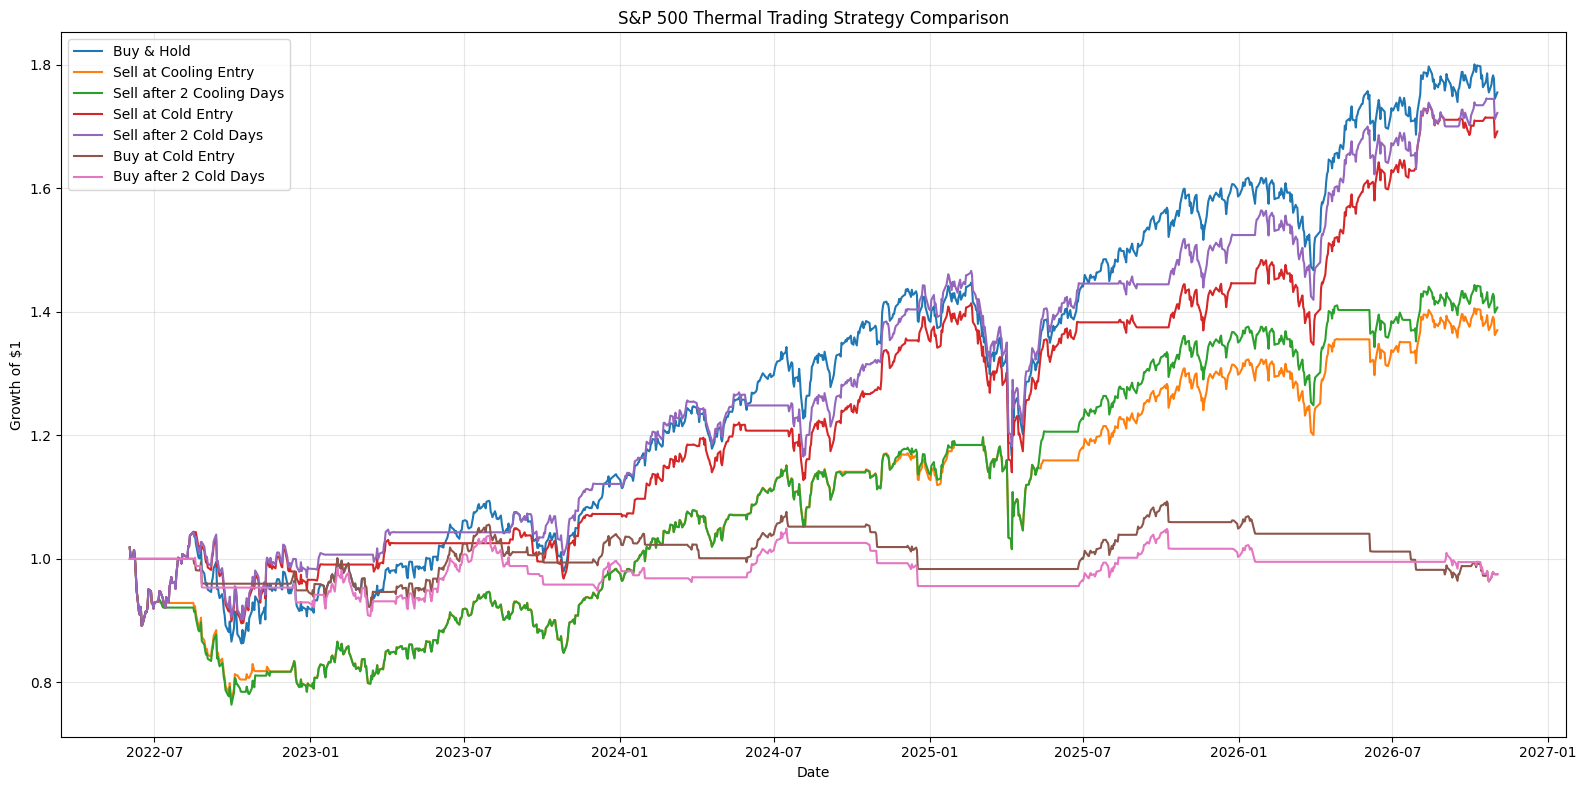

In [ ]:

# ==========================================
# 21. STRATEGY 6: BUY AFTER 2 COLD DAYS
# ==========================================

# Buy only after 2 consecutive COLD observations.
# Remain invested until the COLD regime ends.

bt["Position_Buy_Cold_2D"] = (
    bt["Cold_Confirmed"].astype(int)
)

# Execute signals on the following trading day.
bt["Held_Buy_Cold_2D"] = (
    bt["Position_Buy_Cold_2D"].shift(1).fillna(0)
)

# Calculate turnover and transaction costs.
bt["Turnover_Buy_Cold_2D"] = (
    bt["Held_Buy_Cold_2D"].diff().abs().fillna(0)
)

# Calculate returns.
bt["Strategy_Buy_Cold_2D"] = (
    bt["Held_Buy_Cold_2D"] * bt["Return"]
    - bt["Turnover_Buy_Cold_2D"] * TRANSACTION_COST
)

# Equity curve.
bt["Equity_Buy_Cold_2D"] = (
    1 + bt["Strategy_Buy_Cold_2D"]
).cumprod()


# ==========================================
# 22. UPDATED PERFORMANCE COMPARISON
# ==========================================

results = pd.DataFrame({

    "Buy & Hold": performance_metrics(
        bt["Buy_Hold"],
        pd.Series(1, index=bt.index)
    ),
    "Buy at Cold Entry": performance_metrics(
        bt["Strategy_Buy_Cold"],
        bt["Held_Buy_Cold"]
    ),

    "Buy after 2 Cold Days": performance_metrics(
        bt["Strategy_Buy_Cold_2D"],
        bt["Held_Buy_Cold_2D"]
    )

}).T

display(
    results.style.format({
        "Total Return": "{:.2%}",
        "CAGR": "{:.2%}",
        "Annual Volatility": "{:.2%}",
        "Sharpe Ratio": "{:.2f}",
        "Max Drawdown": "{:.2%}",
        "Market Exposure": "{:.2%}"
    })
)


# ==========================================
# 23. UPDATED EQUITY CURVES
# ==========================================

plt.figure(figsize=(16, 8))

for column, label in [
    ("Equity_Buy_Hold", "Buy & Hold"),
    ("Equity_Entry", "Sell at Cooling Entry"),
    ("Equity_Confirmed", "Sell after 2 Cooling Days"),
    ("Equity_Cold_Entry", "Sell at Cold Entry"),
    ("Equity_Cold_2D", "Sell after 2 Cold Days"),
    ("Equity_Buy_Cold", "Buy at Cold Entry"),
    ("Equity_Buy_Cold_2D", "Buy after 2 Cold Days")
]:

    plt.plot(
        bt.index,
        bt[column],
        label=label,
        linewidth=1.5
    )

plt.title("S&P 500 Thermal Trading Strategy Comparison")
plt.xlabel("Date")
plt.ylabel("Growth of $1")

plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


          S&P 500 THERMAL DYNAMICS MONITOR

--- HEATING RATE ---
Average heating rate: 0.5880 volatility points/day
Maximum daily heating rate: 14.8269 volatility points/day

--- COOLING RATE ---
Average cooling rate: 0.5818 volatility points/day
Maximum daily cooling rate: 15.6214 volatility points/day

--- CURRENT MARKET CONDITIONS ---
Current volatility: 11.73%
Daily volatility change: -0.0523
Current HOT threshold: 14.65%
Current COLD threshold: 10.15%
Current regime: NORMAL

HOT REGIME DURATION
Completed episodes: 18
Average duration: 10.83 days
Median duration: 3.50 days
Longest duration: 47 days
Shortest duration: 1 days
No active episode currently.

COLD REGIME DURATION
Completed episodes: 31
Average duration: 11.52 days
Median duration: 4.00 days
Longest duration: 96 days
Shortest duration: 1 days
No active episode currently.



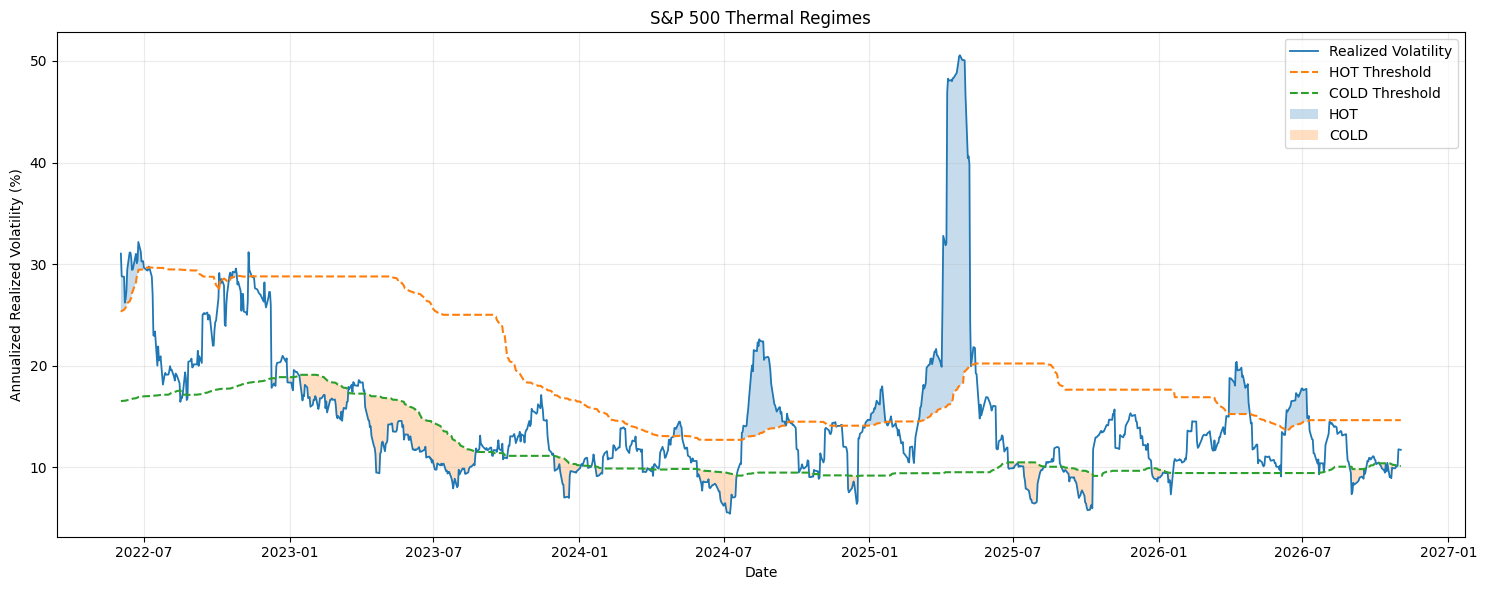

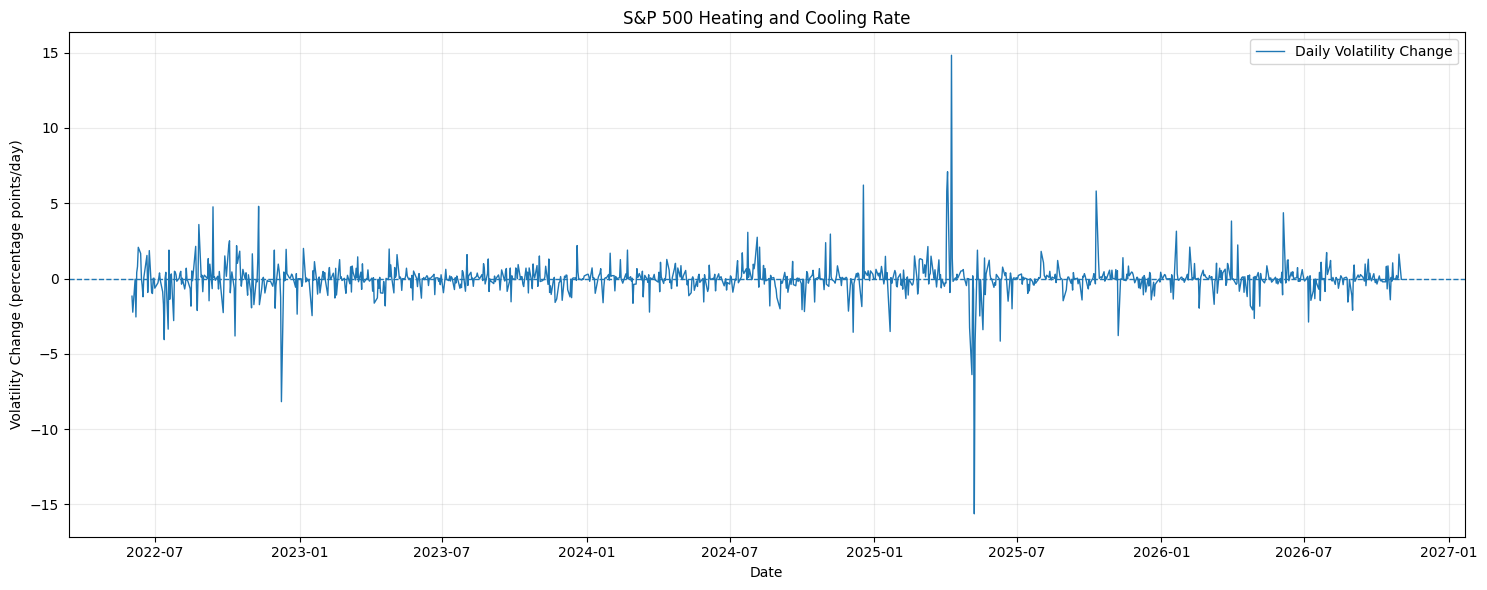

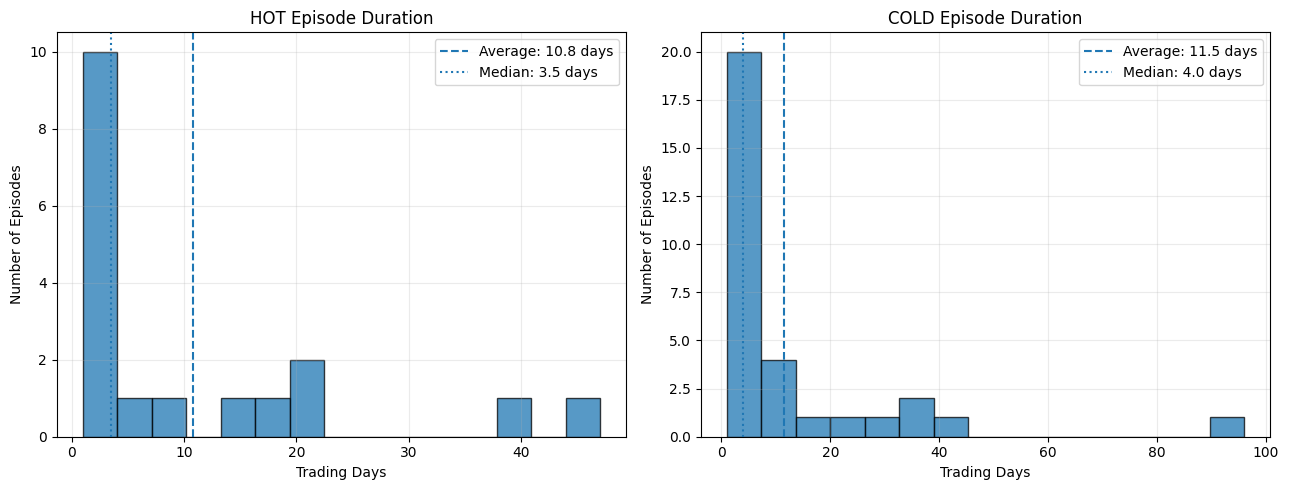

In [ ]:
#rates how long

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ==========================================
# 1. CALCULATE S&P 500 REALIZED VOLATILITY
# ==========================================

close = spx["Close"].squeeze().dropna()

returns = np.log(close / close.shift(1))

# 20-day annualized realized volatility
vol = returns.rolling(20).std() * np.sqrt(252) * 100

data = pd.DataFrame({"Volatility": vol}).dropna()

# Daily change in volatility (percentage points)
data["Vol_Change"] = data["Volatility"].diff()

# ==========================================
# 2. CALCULATE HEATING AND COOLING RATES
# ==========================================

# Positive changes = heating
data["Heating_Rate"] = data["Vol_Change"].clip(lower=0)

# Negative changes = cooling
# Convert to positive values to represent cooling speed.
data["Cooling_Rate"] = -data["Vol_Change"].clip(upper=0)

# Average heating and cooling rates
heating_observations = data["Heating_Rate"].dropna()
cooling_observations = data["Cooling_Rate"].dropna()

average_heating = heating_observations[
    heating_observations > 0
].mean()

average_cooling = cooling_observations[
    cooling_observations > 0
].mean()

max_heating = heating_observations.max()
max_cooling = cooling_observations.max()

# ==========================================
# 3. DEFINE DYNAMIC HOT / COLD THRESHOLDS
# ==========================================

LOOKBACK = 252
MIN_PERIODS = 126

HOT_PERCENTILE = 0.80
COLD_PERCENTILE = 0.20

# Only use historical observations to calculate thresholds.
data["Hot_Threshold"] = (
    data["Volatility"].shift(1)
    .rolling(LOOKBACK, min_periods=MIN_PERIODS)
    .quantile(HOT_PERCENTILE)
)

data["Cold_Threshold"] = (
    data["Volatility"].shift(1)
    .rolling(LOOKBACK, min_periods=MIN_PERIODS)
    .quantile(COLD_PERCENTILE)
)

data = data.dropna().copy()

data["HOT"] = (
    data["Volatility"] >= data["Hot_Threshold"]
)

data["COLD"] = (
    data["Volatility"] <= data["Cold_Threshold"]
)

# ==========================================
# 4. IDENTIFY REGIME EPISODES
# ==========================================

def get_episodes(series, regime_name):

    # Identify continuous periods where condition is True.
    episode_id = series.ne(series.shift()).cumsum()

    episodes = []

    for eid, group in series.groupby(episode_id):

        if not group.iloc[0]:
            continue

        dates = group.index

        episodes.append({
            "Regime": regime_name,
            "Start": dates[0],
            "End": dates[-1],
            "Duration": len(group),
            "Completed": dates[-1] != series.index[-1]
        })

    return pd.DataFrame(episodes)


hot_episodes = get_episodes(data["HOT"], "HOT")
cold_episodes = get_episodes(data["COLD"], "COLD")

episodes = pd.concat(
    [hot_episodes, cold_episodes],
    ignore_index=True
)

# ==========================================
# 5. CALCULATE REGIME DURATION STATISTICS
# ==========================================

def duration_statistics(episodes, regime):

    regime_data = episodes[
        episodes["Regime"] == regime
    ]

    completed = regime_data[
        regime_data["Completed"]
    ]["Duration"]

    current = regime_data[
        ~regime_data["Completed"]
    ]

    print(f"\n{regime} REGIME DURATION")

    print(f"Completed episodes: {len(completed)}")

    if len(completed) > 0:

        print(f"Average duration: {completed.mean():.2f} days")
        print(f"Median duration: {completed.median():.2f} days")
        print(f"Longest duration: {completed.max()} days")
        print(f"Shortest duration: {completed.min()} days")

    if len(current) > 0:

        print(
            f"Current episode age: "
            f"{int(current.iloc[0]['Duration'])} days"
        )

    else:
        print("No active episode currently.")


# ==========================================
# 6. PRINT THERMAL MARKET REPORT
# ==========================================

print("=" * 55)
print("          S&P 500 THERMAL DYNAMICS MONITOR")
print("=" * 55)

print("\n--- HEATING RATE ---")

print(
    f"Average heating rate: "
    f"{average_heating:.4f} volatility points/day"
)

print(
    f"Maximum daily heating rate: "
    f"{max_heating:.4f} volatility points/day"
)

print("\n--- COOLING RATE ---")

print(
    f"Average cooling rate: "
    f"{average_cooling:.4f} volatility points/day"
)

print(
    f"Maximum daily cooling rate: "
    f"{max_cooling:.4f} volatility points/day"
)

print("\n--- CURRENT MARKET CONDITIONS ---")

current_vol = data["Volatility"].iloc[-1]
current_change = data["Vol_Change"].iloc[-1]

print(f"Current volatility: {current_vol:.2f}%")
print(f"Daily volatility change: {current_change:+.4f}")

print(
    f"Current HOT threshold: "
    f"{data['Hot_Threshold'].iloc[-1]:.2f}%"
)

print(
    f"Current COLD threshold: "
    f"{data['Cold_Threshold'].iloc[-1]:.2f}%"
)

if data["HOT"].iloc[-1]:
    print("Current regime: HOT")
elif data["COLD"].iloc[-1]:
    print("Current regime: COLD")
else:
    print("Current regime: NORMAL")

duration_statistics(episodes, "HOT")
duration_statistics(episodes, "COLD")

print("\n" + "=" * 55)

# ==========================================
# 7. PLOT VOLATILITY AND REGIME THRESHOLDS
# ==========================================

fig, ax = plt.subplots(figsize=(15, 6))

ax.plot(
    data.index,
    data["Volatility"],
    label="Realized Volatility",
    linewidth=1.3
)

ax.plot(
    data.index,
    data["Hot_Threshold"],
    linestyle="--",
    label="HOT Threshold"
)

ax.plot(
    data.index,
    data["Cold_Threshold"],
    linestyle="--",
    label="COLD Threshold"
)

ax.fill_between(
    data.index,
    data["Volatility"],
    data["Hot_Threshold"],
    where=data["HOT"],
    alpha=0.25,
    label="HOT"
)

ax.fill_between(
    data.index,
    data["Volatility"],
    data["Cold_Threshold"],
    where=data["COLD"],
    alpha=0.25,
    label="COLD"
)

ax.set_title("S&P 500 Thermal Regimes")
ax.set_xlabel("Date")
ax.set_ylabel("Annualized Realized Volatility (%)")
ax.legend()
ax.grid(alpha=0.25)

plt.tight_layout()
plt.show()

# ==========================================
# 8. PLOT HEATING / COOLING RATE
# ==========================================

fig, ax = plt.subplots(figsize=(15, 6))

ax.plot(
    data.index,
    data["Vol_Change"],
    label="Daily Volatility Change",
    linewidth=1
)

ax.axhline(0, linestyle="--", linewidth=1)

ax.set_title("S&P 500 Heating and Cooling Rate")
ax.set_xlabel("Date")
ax.set_ylabel("Volatility Change (percentage points/day)")
ax.legend()
ax.grid(alpha=0.25)

plt.tight_layout()
plt.show()

# ==========================================
# 9. PLOT REGIME DURATION DISTRIBUTIONS
# ==========================================

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

for ax, regime in zip(axes, ["HOT", "COLD"]):

    durations = episodes[
        (episodes["Regime"] == regime) &
        (episodes["Completed"])
    ]["Duration"]

    if len(durations) > 0:

        ax.hist(
            durations,
            bins=min(15, max(3, len(durations))),
            edgecolor="black",
            alpha=0.75
        )

        ax.axvline(
            durations.mean(),
            linestyle="--",
            label=f"Average: {durations.mean():.1f} days"
        )

        ax.axvline(
            durations.median(),
            linestyle=":",
            label=f"Median: {durations.median():.1f} days"
        )

        ax.legend()

    ax.set_title(f"{regime} Episode Duration")
    ax.set_xlabel("Trading Days")
    ax.set_ylabel("Number of Episodes")
    ax.grid(alpha=0.25)

plt.tight_layout()
plt.show()
